In [ ]:

!pip -q install transformers scikit-learn pandas matplotlib seaborn ipywidgets accelerate

In [ ]:

import os, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 2
LEARNING_RATE = 2e-5
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("Note: BERT training on CPU can be slow. In Colab, select Runtime > Change runtime type > T4 GPU if available.")

Device: cuda


In [ ]:

try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("No CSV file was uploaded. Please upload your email dataset as a .csv file.")
    CSV_PATH = csv_files[0]
except ImportError:

    CSV_PATH = "messages.csv"

df_raw = pd.read_csv(CSV_PATH)
print("Loaded:", CSV_PATH, "| Shape:", df_raw.shape)
display(df_raw.head())
print("Columns:", df_raw.columns.tolist())

Saving enron_spam_data.csv to enron_spam_data.csv
Loaded: enron_spam_data.csv | Shape: (33716, 5)


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


Columns: ['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date']


In [ ]:
print("Column names:", df_raw.columns.tolist())
display(df_raw.head(3))

Column names: ['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date']


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14


In [ ]:


df_raw["Subject"] = df_raw["Subject"].fillna("")
df_raw["Message"] = df_raw["Message"].fillna("")


df_raw = df_raw.dropna(subset=["Spam/Ham"])


df_raw["email_text"] = (
    df_raw["Subject"].astype(str) + " " +
    df_raw["Message"].astype(str)
).str.strip()

print("Dataset shape:", df_raw.shape)
print("\nLabel distribution:")
print(df_raw["Spam/Ham"].value_counts())
display(df_raw[["Subject", "Message", "Spam/Ham", "email_text"]].head())


Dataset shape: (33716, 6)

Label distribution:
Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64


,Subject,Message,Spam/Ham,email_text
0,christmas tree farm pictures,,ham,christmas tree farm pictures
1,"vastar resources , inc .","gary , production from the high island larger ...",ham,"vastar resources , inc . gary , production fro..."
2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,calpine daily gas nomination - calpine daily g...
3,re : issue,fyi - see note below - already done .\nstella\...,ham,re : issue fyi - see note below - already done...
4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,meter 7268 nov allocation fyi .\n- - - - - - -...


In [ ]:

import pandas as pd


df = df_raw[["email_text", "Spam/Ham"]].copy()


df["email_text"] = df["email_text"].fillna("").astype(str).str.strip()
df["Spam/Ham"] = df["Spam/Ham"].astype(str).str.strip().str.lower()


df = df[df["Spam/Ham"].isin(["spam", "ham"])]
df = df[df["email_text"] != ""]


print("Rows before duplicate removal:", len(df))
print("Duplicate email texts:", df["email_text"].duplicated().sum())


df = df.drop_duplicates(subset=["email_text"]).reset_index(drop=True)


df["label"] = df["Spam/Ham"].map({"ham": 0, "spam": 1})

print("\nClean dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Spam/Ham"].value_counts())
print("\nMissing values:")
print(df[["email_text", "label"]].isna().sum())
display(df.head())


Rows before duplicate removal: 33665
Duplicate email texts: 3203

Clean dataset shape: (30462, 3)

Class distribution:
Spam/Ham
ham     15910
spam    14552
Name: count, dtype: int64

Missing values:
email_text    0
label         0
dtype: int64


,email_text,Spam/Ham,label
0,christmas tree farm pictures,ham,0
1,"vastar resources , inc . gary , production fro...",ham,0
2,calpine daily gas nomination - calpine daily g...,ham,0
3,re : issue fyi - see note below - already done...,ham,0
4,meter 7268 nov allocation fyi .\n- - - - - - -...,ham,0


In [ ]:

from sklearn.model_selection import train_test_split


train_val, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["label"]
)


train_df, val_df = train_test_split(
    train_val,
    test_size=0.17647,
    random_state=42,
    stratify=train_val["label"]
)

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

print("\nTraining label proportions:")
print(train_df["Spam/Ham"].value_counts(normalize=True).round(3))

print("\nValidation label proportions:")
print(val_df["Spam/Ham"].value_counts(normalize=True).round(3))

print("\nTesting label proportions:")
print(test_df["Spam/Ham"].value_counts(normalize=True).round(3))


Training rows: 21322
Validation rows: 4570
Testing rows: 4570

Training label proportions:
Spam/Ham
ham     0.522
spam    0.478
Name: proportion, dtype: float64

Validation label proportions:
Spam/Ham
ham     0.522
spam    0.478
Name: proportion, dtype: float64

Testing label proportions:
Spam/Ham
ham     0.522
spam    0.478
Name: proportion, dtype: float64


In [ ]:

%pip install -q transformers scikit-learn


In [ ]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab, select Runtime > Change runtime type > T4 GPU (if available).")


PyTorch version: 2.11.0+cu130
Selected device: cuda
GPU: Tesla T4


In [ ]:

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_encoder = AutoModel.from_pretrained(MODEL_NAME)

bert_encoder = bert_encoder.to(device)

print("BERT tokenizer loaded successfully.")
print("BERT hidden size:", bert_encoder.config.hidden_size)
print("Device:", next(bert_encoder.parameters()).device)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT tokenizer loaded successfully.
BERT hidden size: 768
Device: cuda:0


In [ ]:

import torch
import torch.nn as nn
from transformers import AutoModel

class BertRNNClassifier(nn.Module):
    def __init__(self, model_name="bert-base-uncased",
                 rnn_type="LSTM", hidden_size=128,
                 dropout=0.3, num_classes=2):
        super().__init__()

        self.bert = AutoModel.from_pretrained(model_name)

        if rnn_type not in ["LSTM", "BiLSTM"]:
            raise ValueError("rnn_type must be 'LSTM' or 'BiLSTM'")

        bidirectional = (rnn_type == "BiLSTM")

        self.rnn = nn.LSTM(
            input_size=self.bert.config.hidden_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=bidirectional
        )

        output_size = hidden_size * (2 if bidirectional else 1)

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(output_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = outputs.last_hidden_state


        lengths = attention_mask.sum(dim=1).clamp(min=1) - 1
        batch_indices = torch.arange(
            sequence_output.size(0), device=sequence_output.device
        )

        last_valid = sequence_output[batch_indices, lengths]
        logits = self.classifier(self.dropout(last_valid))

        return logits


bert_lstm = BertRNNClassifier(rnn_type="LSTM").to(device)
bert_bilstm = BertRNNClassifier(rnn_type="BiLSTM").to(device)

print("BERT-LSTM created.")
print("BERT-BiLSTM created.")
print("LSTM parameters:", sum(p.numel() for p in bert_lstm.parameters()))
print("BiLSTM parameters:", sum(p.numel() for p in bert_bilstm.parameters()))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT-LSTM created.
BERT-BiLSTM created.
LSTM parameters: 109942274
BiLSTM parameters: 110402306


In [ ]:

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = outputs.last_hidden_state

        rnn_output, (hidden, cell) = self.rnn(sequence_output)

        if self.rnn.bidirectional:

            features = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            features = hidden[-1]

        logits = self.classifier(self.dropout(features))
        return logits


In [ ]:

LABEL_COLUMN = "Spam/Ham"
SUBJECT_COLUMN = "Subject"
TEXT_COLUMN = "Message"


In [ ]:


LABEL_COLUMN = "Spam/Ham"
SUBJECT_COLUMN = "Subject"
TEXT_COLUMN = "Message"


print("CSV columns:", df_raw.columns.tolist())

assert LABEL_COLUMN in df_raw.columns, (
    f"Missing label column. Available columns: {df_raw.columns.tolist()}"
)
assert SUBJECT_COLUMN in df_raw.columns
assert TEXT_COLUMN in df_raw.columns

print("Detected label column:", LABEL_COLUMN)
print("Detected subject column:", SUBJECT_COLUMN)
print("Detected body/text column:", TEXT_COLUMN)


CSV columns: ['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date', 'email_text']
Detected label column: Spam/Ham
Detected subject column: Subject
Detected body/text column: Message


In [ ]:


lower_to_original = {str(c).strip().lower(): c for c in df_raw.columns}

def find_col(candidates):
    for name in candidates:
        if name in lower_to_original:
            return lower_to_original[name]
    return None

LABEL_COLUMN = find_col([
    "spam/ham", "label", "labels", "class",
    "category", "target", "spam", "is_spam"
])
SUBJECT_COLUMN = find_col(["subject", "email_subject", "title"])
TEXT_COLUMN = find_col(["message", "text", "email", "body", "content", "email_text", "v2"])


print("Detected label column:", LABEL_COLUMN)
print("Detected subject column:", SUBJECT_COLUMN)
print("Detected body/text column:", TEXT_COLUMN)

if LABEL_COLUMN is None:
    raise ValueError("Could not detect the label column. Set LABEL_COLUMN to the exact column name in your CSV.")
if TEXT_COLUMN is None and SUBJECT_COLUMN is None:
    raise ValueError("Could not detect a text or subject column. Set TEXT_COLUMN / SUBJECT_COLUMN to the exact column name.")

df = df_raw.copy()
text_parts = []
if SUBJECT_COLUMN is not None:
    text_parts.append(df[SUBJECT_COLUMN].fillna("").astype(str))
if TEXT_COLUMN is not None and TEXT_COLUMN != SUBJECT_COLUMN:
    text_parts.append(df[TEXT_COLUMN].fillna("").astype(str))
df["text"] = text_parts[0]
for part in text_parts[1:]:
    df["text"] = df["text"] + " " + part

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, np.integer, float, np.floating)) and value in (0, 1):
        return int(value)
    s = str(value).strip().lower()
    spam_values = {"spam", "junk", "unsolicited", "1", "true", "yes", "phishing"}
    ham_values = {"ham", "not spam", "not_spam", "legitimate", "legit", "0", "false", "no", "non-spam", "nonspam"}
    if s in spam_values:
        return 1
    if s in ham_values:
        return 0
    return np.nan

df["label"] = df[LABEL_COLUMN].apply(normalize_label)
before = len(df)
df = df.dropna(subset=["label", "text"]).copy()
df["label"] = df["label"].astype(int)
df["text"] = df["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["text"].str.len() > 0].drop_duplicates(subset=["text", "label"]).reset_index(drop=True)

if df["label"].nunique() != 2:
    raise ValueError("After label mapping, the dataset must contain both classes: ham/legitimate (0) and spam (1). Check your label values.")
if df["label"].value_counts().min() < 3:
    raise ValueError("Need at least 3 examples in each class for stratified train/validation/test splitting.")

print(f"Usable rows: {len(df)} (removed {before-len(df)} rows with unsupported/missing labels or empty text)")
print("Label mapping: 0 = HAM / legitimate; 1 = SPAM")
display(df[["text", "label"]].head())
display(df["label"].value_counts().rename(index={0:"HAM", 1:"SPAM"}).to_frame("count"))

Detected label column: Spam/Ham
Detected subject column: Subject
Detected body/text column: Message
Usable rows: 30137 (removed 3579 rows with unsupported/missing labels or empty text)
Label mapping: 0 = HAM / legitimate; 1 = SPAM


,text,label
0,christmas tree farm pictures,0
1,"vastar resources , inc . gary , production fro...",0
2,calpine daily gas nomination - calpine daily g...,0
3,re : issue fyi - see note below - already done...,0
4,meter 7268 nov allocation fyi . - - - - - - - ...,0


,count
label,
HAM,15590
SPAM,14547


In [ ]:

train_df, temp_df = train_test_split(
    df, test_size=TEST_SIZE + VALIDATION_SIZE, random_state=SEED, stratify=df["label"]
)
relative_test = TEST_SIZE / (TEST_SIZE + VALIDATION_SIZE)
val_df, test_df = train_test_split(
    temp_df, test_size=relative_test, random_state=SEED, stratify=temp_df["label"]
)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
print("Train class proportions:")
display(train_df["label"].value_counts(normalize=True).rename(index={0:"HAM", 1:"SPAM"}).to_frame("proportion"))

Train: 21095 | Validation: 4521 | Test: 4521
Train class proportions:


,proportion
label,
HAM,0.517326
SPAM,0.482674


In [ ]:

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class EmailDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=128):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_attention_mask=True,
            return_tensors="pt"
        )
        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(EmailDataset(train_df, tokenizer, MAX_LENGTH), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(EmailDataset(val_df, tokenizer, MAX_LENGTH), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(EmailDataset(test_df, tokenizer, MAX_LENGTH), batch_size=BATCH_SIZE, shuffle=False)

print("Tokenizer and data loaders are ready.")

Tokenizer and data loaders are ready.


In [ ]:

class BertRecurrentClassifier(nn.Module):
    def __init__(self, model_name, bidirectional=False, hidden_size=128, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.bidirectional = bidirectional
        bert_hidden = self.bert.config.hidden_size
        self.lstm = nn.LSTM(
            input_size=bert_hidden,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=bidirectional
        )
        recurrent_out = hidden_size * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(recurrent_out, 2)

    def forward(self, input_ids, attention_mask):
        bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence = bert_out.last_hidden_state
        lengths = attention_mask.sum(dim=1).clamp(min=1).cpu()

        # Packed sequences prevent the recurrent layer from treating right-padding as real text.
        packed = nn.utils.rnn.pack_padded_sequence(
            sequence, lengths, batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)

        if self.bidirectional:
            # Last layer's forward and backward final states
            representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            representation = hidden[-1]

        return self.classifier(self.dropout(representation))

def build_model(kind):
    if kind == "BERT + LSTM":
        return BertRecurrentClassifier(MODEL_NAME, bidirectional=False).to(DEVICE)
    elif kind == "BERT + BiLSTM":
        return BertRecurrentClassifier(MODEL_NAME, bidirectional=True).to(DEVICE)
    raise ValueError("Unknown model kind")

print("Model class defined.")

Model class defined.


In [ ]:

def run_epoch(model, loader, optimizer=None, scheduler=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss = 0.0
    all_labels, all_preds = [], []
    criterion = nn.CrossEntropyLoss()

    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()

        total_loss += loss.item() * labels.size(0)
        preds = torch.argmax(logits, dim=1)
        all_labels.extend(labels.detach().cpu().tolist())
        all_preds.extend(preds.detach().cpu().tolist())

    return total_loss / len(loader.dataset), np.array(all_labels), np.array(all_preds)

def train_model(kind):
    print("\n" + "="*70 + "\nTraining:", kind)
    model = build_model(kind)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=max(0, int(0.1 * total_steps)), num_training_steps=total_steps
    )

    best_val_f1 = -1
    best_state = None
    history = []

    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        train_loss, train_y, train_pred = run_epoch(model, train_loader, optimizer, scheduler)
        val_loss, val_y, val_pred = run_epoch(model, val_loader)
        val_f1 = f1_score(val_y, val_pred, zero_division=0)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": accuracy_score(train_y, train_pred),
            "val_accuracy": accuracy_score(val_y, val_pred),
            "val_f1": val_f1,
            "seconds": time.time() - start
        })
        print(f"Epoch {epoch}/{EPOCHS} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | "
              f"val accuracy={accuracy_score(val_y, val_pred):.4f} | val F1={val_f1:.4f}")
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    model.to(DEVICE)
    history_df = pd.DataFrame(history)
    return model, history_df

def evaluate_model(model, loader, model_name):
    model.eval()
    y_true, y_pred = [], []
    batch_latencies = []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["label"].cpu().numpy()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()
            logits = model(input_ids, attention_mask)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            batch_latencies.append((time.perf_counter() - start) / len(labels))
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Avg inference sec/email": float(np.mean(batch_latencies))
    }
    print(f"\n{model_name} classification report:")
    print(classification_report(y_true, y_pred, target_names=["HAM", "SPAM"], zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["HAM", "SPAM"], yticklabels=["HAM", "SPAM"])
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()
    return metrics


Training: BERT + LSTM


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/2 | train loss=0.1135 | val loss=0.0639 | val accuracy=0.9847 | val F1=0.9840
Epoch 2/2 | train loss=0.0176 | val loss=0.0423 | val accuracy=0.9909 | val F1=0.9906

Training: BERT + BiLSTM


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Epoch 1/2 | train loss=0.1123 | val loss=0.0317 | val accuracy=0.9918 | val F1=0.9915
Epoch 2/2 | train loss=0.0155 | val loss=0.0405 | val accuracy=0.9923 | val F1=0.9920
BERT + LSTM training history


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_f1,seconds
0,1,0.113481,0.063896,0.961982,0.984738,0.983994,640.131536
1,2,0.017605,0.042257,0.996587,0.990931,0.990564,637.257155


BERT + BiLSTM training history


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_f1,seconds
0,1,0.112322,0.03167,0.963593,0.991816,0.991516,645.360569
1,2,0.015479,0.04050,0.996634,0.992258,0.991952,645.952112



BERT + LSTM classification report:
              precision    recall  f1-score   support

         HAM       0.99      0.99      0.99      2339
        SPAM       0.99      0.99      0.99      2182

    accuracy                           0.99      4521
   macro avg       0.99      0.99      0.99      4521
weighted avg       0.99      0.99      0.99      4521



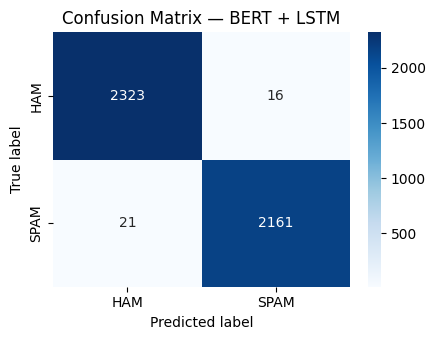


BERT + BiLSTM classification report:
              precision    recall  f1-score   support

         HAM       0.99      0.99      0.99      2339
        SPAM       0.99      0.99      0.99      2182

    accuracy                           0.99      4521
   macro avg       0.99      0.99      0.99      4521
weighted avg       0.99      0.99      0.99      4521



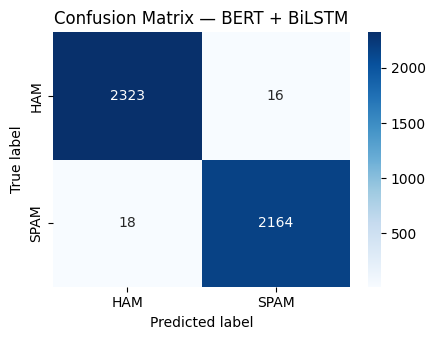

Final comparison (held-out test set):


,Model,Accuracy,Precision,Recall,F1-score,Avg inference sec/email
0,BERT + LSTM,0.9918,0.9927,0.9904,0.9915,0.0071
1,BERT + BiLSTM,0.9925,0.9927,0.9918,0.9922,0.0072


In [ ]:

lstm_model, lstm_history = train_model("BERT + LSTM")
bilstm_model, bilstm_history = train_model("BERT + BiLSTM")

print("BERT + LSTM training history")
display(lstm_history)
print("BERT + BiLSTM training history")
display(bilstm_history)

lstm_metrics = evaluate_model(lstm_model, test_loader, "BERT + LSTM")
bilstm_metrics = evaluate_model(bilstm_model, test_loader, "BERT + BiLSTM")

results_df = pd.DataFrame([lstm_metrics, bilstm_metrics])
print("Final comparison (held-out test set):")
display(results_df.round(4))

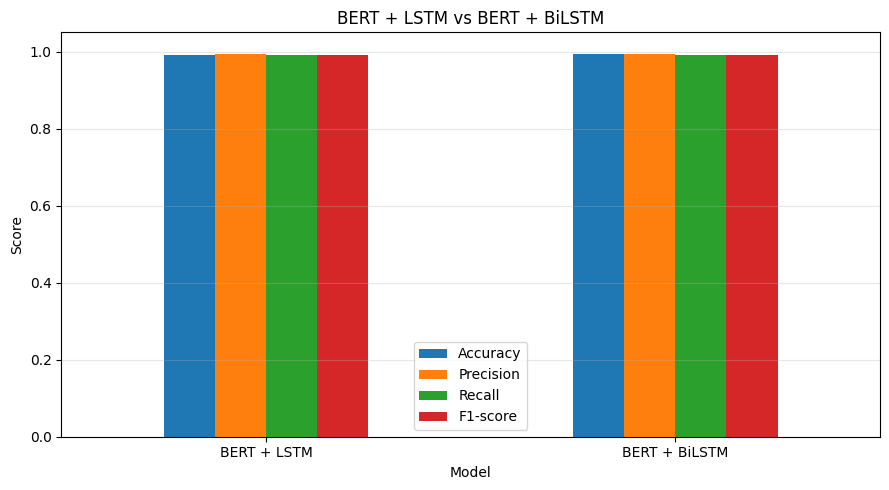

Saved results to model_comparison_results.csv


In [ ]:

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
results_df.set_index("Model")[metrics_to_plot].plot(kind="bar", figsize=(9, 5), ylim=(0, 1.05))
plt.title("BERT + LSTM vs BERT + BiLSTM")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

results_df.to_csv("model_comparison_results.csv", index=False)
print("Saved results to model_comparison_results.csv")

In [ ]:

def predict_email(email_text, model, threshold=0.5):
    model.eval()
    encoded = tokenizer(
        str(email_text), truncation=True, padding="max_length",
        max_length=MAX_LENGTH, return_attention_mask=True, return_tensors="pt"
    )
    input_ids = encoded["input_ids"].to(DEVICE)
    attention_mask = encoded["attention_mask"].to(DEVICE)
    with torch.no_grad():
        logits = model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    predicted = int(np.argmax(probs))
    label = "SPAM" if predicted == 1 else "HAM / legitimate"
    return {"prediction": label, "spam_probability": float(probs[1]), "ham_probability": float(probs[0])}

sample_email = "Congratulations! You have won a free prize. Click this link now to claim your reward."
print("BERT + LSTM:", predict_email(sample_email, lstm_model))
print("BERT + BiLSTM:", predict_email(sample_email, bilstm_model))

BERT + LSTM: {'prediction': 'SPAM', 'spam_probability': 0.998369038105011, 'ham_probability': 0.001631035702303052}
BERT + BiLSTM: {'prediction': 'SPAM', 'spam_probability': 0.9796808958053589, 'ham_probability': 0.020319048315286636}


In [ ]:

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    email_box = widgets.Textarea(
        value="",
        placeholder="Paste the email subject and body here...",
        description="Email:",
        layout=widgets.Layout(width="100%", height="130px")
    )
    model_choice = widgets.Dropdown(
        options=["BERT + LSTM", "BERT + BiLSTM"],
        value="BERT + LSTM",
        description="Model:"
    )
    predict_button = widgets.Button(description="Classify email", button_style="primary")
    output = widgets.Output()

    def on_predict_clicked(_):
        with output:
            clear_output()
            if not email_box.value.strip():
                print("Please enter an email first.")
                return
            selected_model = lstm_model if model_choice.value == "BERT + LSTM" else bilstm_model
            result = predict_email(email_box.value, selected_model)
            print("Prediction:", result["prediction"])
            print(f"Spam probability: {result['spam_probability']:.2%}")
            print(f"HAM probability: {result['ham_probability']:.2%}")
            print("Note: This is a model prediction, not a guarantee. Verify suspicious emails carefully.")

    predict_button.on_click(on_predict_clicked)
    display(model_choice, email_box, predict_button, output)
except Exception as e:
    print("Interactive widgets could not be displayed in this environment:", e)

Dropdown(description='Model:', options=('BERT + LSTM', 'BERT + BiLSTM'), value='BERT + LSTM')

Textarea(value='', description='Email:', layout=Layout(height='130px', width='100%'), placeholder='Paste the e…

Button(button_style='primary', description='Classify email', style=ButtonStyle())

Output()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "F1-score (%)": round(f1_score(y_true, y_pred, zero_division=0) * 100, 2)
    }


BERT-LSTM: classification report
              precision    recall  f1-score   support

         HAM       0.99      0.99      0.99      2339
        SPAM       0.99      0.99      0.99      2182

    accuracy                           0.99      4521
   macro avg       0.99      0.99      0.99      4521
weighted avg       0.99      0.99      0.99      4521


BERT-BiLSTM: classification report
              precision    recall  f1-score   support

         HAM       0.99      0.99      0.99      2339
        SPAM       0.99      0.99      0.99      2182

    accuracy                           0.99      4521
   macro avg       0.99      0.99      0.99      4521
weighted avg       0.99      0.99      0.99      4521


FINAL TEST RESULTS


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Inference time (s),Inference (ms/email)
0,BERT-LSTM,99.1816,99.2650,99.0376,99.1512,38.4506,8.5049
1,BERT-BiLSTM,99.2480,99.2661,99.1751,99.2205,38.9900,8.6242


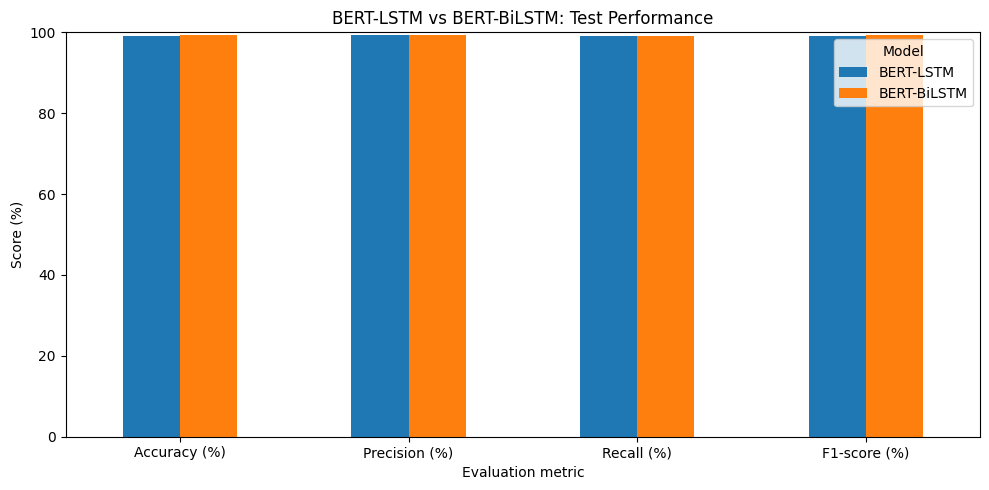

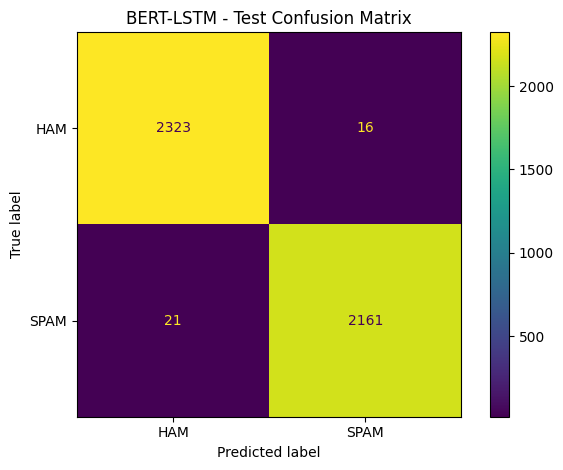

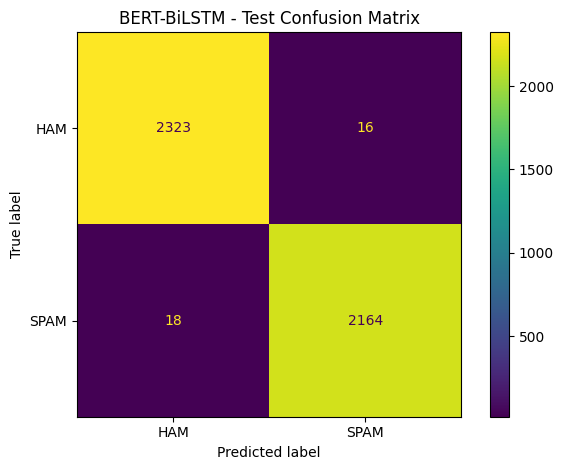

Saved:
- spam_model_comparison.csv
- model_performance_comparison.png
- bert_lstm_confusion_matrix.png
- bert_bilstm_confusion_matrix.png


In [ ]:

import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from IPython.display import display

# Confirm that training has created both models
assert "lstm_model" in globals(), "Train BERT-LSTM first."
assert "bilstm_model" in globals(), "Train BERT-BiLSTM first."
assert "test_loader" in globals(), "Create test_loader first."

def get_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    start = time.perf_counter()

    with torch.inference_mode():
        for batch in loader:
            # Support dictionary batches and TensorDataset batches
            if isinstance(batch, dict):
                input_ids = batch["input_ids"]
                attention_mask = batch["attention_mask"]
                labels = batch.get("labels", batch.get("label"))
                if labels is None:
                    raise ValueError("Test batch has no labels.")
            else:
                input_ids, attention_mask, labels = batch[:3]

            model_device = next(model.parameters()).device
            input_ids = input_ids.to(model_device)
            attention_mask = attention_mask.to(model_device)
            labels = labels.to(model_device)

            outputs = model(input_ids, attention_mask)

            if hasattr(outputs, "logits"):
                logits = outputs.logits
            elif isinstance(outputs, (tuple, list)):
                logits = outputs[0]
            else:
                logits = outputs

            predictions = logits.argmax(dim=1)
            y_true.extend(labels.detach().cpu().numpy().tolist())
            y_pred.extend(predictions.detach().cpu().numpy().tolist())

    elapsed = time.perf_counter() - start
    return np.array(y_true), np.array(y_pred), elapsed


def evaluate_one(model, name):
    y_true, y_pred, elapsed = get_predictions(model, test_loader)

    metrics = {
        "Model": name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(
            y_true, y_pred, zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_true, y_pred, zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_true, y_pred, zero_division=0
        ) * 100,
        "Inference time (s)": elapsed,
        "Inference (ms/email)": elapsed / len(y_true) * 1000
    }

    print(f"\n{name}: classification report")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["HAM", "SPAM"],
        zero_division=0
    ))

    return metrics, y_true, y_pred


# Evaluate both models on the same held-out test loader
lstm_result, y_true_lstm, y_pred_lstm = evaluate_one(
    lstm_model, "BERT-LSTM"
)
bilstm_result, y_true_bilstm, y_pred_bilstm = evaluate_one(
    bilstm_model, "BERT-BiLSTM"
)

# Confirm both evaluations used the same true test labels
assert np.array_equal(y_true_lstm, y_true_bilstm), (
    "The test labels differ between models. Check the test loader."
)

results_df = pd.DataFrame([lstm_result, bilstm_result])
results_df = results_df.round(4)

print("\nFINAL TEST RESULTS")
display(results_df)

# Export the numerical table
results_df.to_csv("spam_model_comparison.csv", index=False)

# Figure 1: compare classification metrics
metric_cols = [
    "Accuracy (%)", "Precision (%)",
    "Recall (%)", "F1-score (%)"
]

plot_df = results_df.set_index("Model")[metric_cols]
ax = plot_df.T.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation metric")
ax.set_title("BERT-LSTM vs BERT-BiLSTM: Test Performance")
ax.set_ylim(0, 100)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

# Figures 2 and 3: confusion matrices
for name, y_true, y_pred, filename in [
    ("BERT-LSTM", y_true_lstm, y_pred_lstm,
     "bert_lstm_confusion_matrix.png"),
    ("BERT-BiLSTM", y_true_bilstm, y_pred_bilstm,
     "bert_bilstm_confusion_matrix.png")
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["HAM", "SPAM"]
    )
    display_plot.plot(values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

print("Saved:")
print("- spam_model_comparison.csv")
print("- model_performance_comparison.png")
print("- bert_lstm_confusion_matrix.png")
print("- bert_bilstm_confusion_matrix.png")
